# Шестой этап: Langfuse, анализ ошибок и итоговый отчёт

Ноутбук объединяет результаты всех этапов, содержит графики и показывает структуру Langfuse traces. 

In [2]:
from pathlib import Path
import csv
import json
import os
import subprocess
import sys

import matplotlib.pyplot as plt

# Находим корень проекта независимо от каталога запуска Jupyter.
candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((path for path in candidates if (path / 'pyproject.toml').exists()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Не найден pyproject.toml')
os.chdir(PROJECT_ROOT)
ANALYSIS_DIR = PROJECT_ROOT / 'reports/results/analysis'
FIGURES_DIR = ANALYSIS_DIR / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f'Корень: {PROJECT_ROOT}')
print(f'Python: {sys.version.split()[0]}')

Корень: /Users/e.ilyina/Desktop/Портфолио/RAG
Python: 3.13.0


## 1. Бесплатный лимит Langfuse Cloud

In [3]:
summary = json.loads((ANALYSIS_DIR / 'stage_6_summary.json').read_text(encoding='utf-8'))
hobby = summary['langfuse_hobby']
print(json.dumps(hobby, ensure_ascii=False, indent=2))
assert hobby['estimated_import_units'] < hobby['monthly_included_units']

{
  "data_access_days": 30,
  "estimated_allowance_percent": 0.192,
  "estimated_import_units": 96,
  "monthly_included_units": 50000
}


## 2. Сравнение retrieval

Сравниваем nDCG@10 и Recall@10: первая метрика учитывает порядок релевантных документов, вторая — полноту первой десятки.

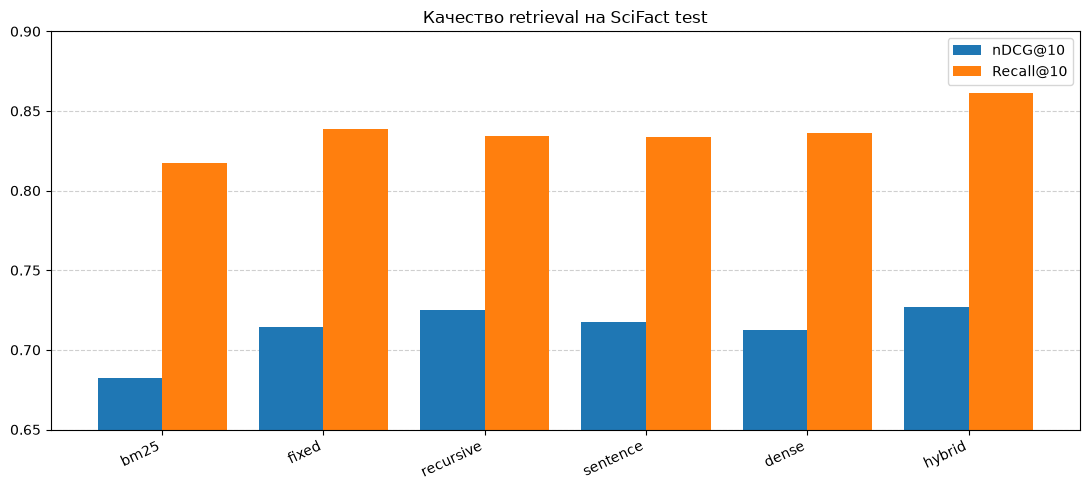

Сохранено: /Users/e.ilyina/Desktop/Портфолио/RAG/reports/results/analysis/figures/retrieval_quality.png


In [4]:
with (ANALYSIS_DIR / 'retrieval_comparison.csv').open(encoding='utf-8') as source:
    retrieval = list(csv.DictReader(source))
methods = [row['method'].replace('_document', '').replace('chunk_', '') for row in retrieval]
ndcg = [float(row['ndcg_at_10']) for row in retrieval]
recall = [float(row['recall_at_10']) for row in retrieval]
x = list(range(len(methods)))
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar([value - 0.2 for value in x], ndcg, width=0.4, label='nDCG@10')
ax.bar([value + 0.2 for value in x], recall, width=0.4, label='Recall@10')
ax.set_xticks(x, methods, rotation=25, ha='right')
ax.set_ylim(0.65, 0.9)
ax.grid(axis='y', linestyle='--', linewidth=0.8, alpha=0.6)
ax.set_axisbelow(True)
ax.set_title('Качество retrieval на SciFact test')
ax.legend()
fig.tight_layout()
figure_path = FIGURES_DIR / 'retrieval_quality.png'
fig.savefig(figure_path, dpi=140)
plt.show()
print('Сохранено:', figure_path)

## 3. Ручные оценки RAG

Оценки 0–2 выставлены после сопоставления каждого ответа с фактически переданными источниками.

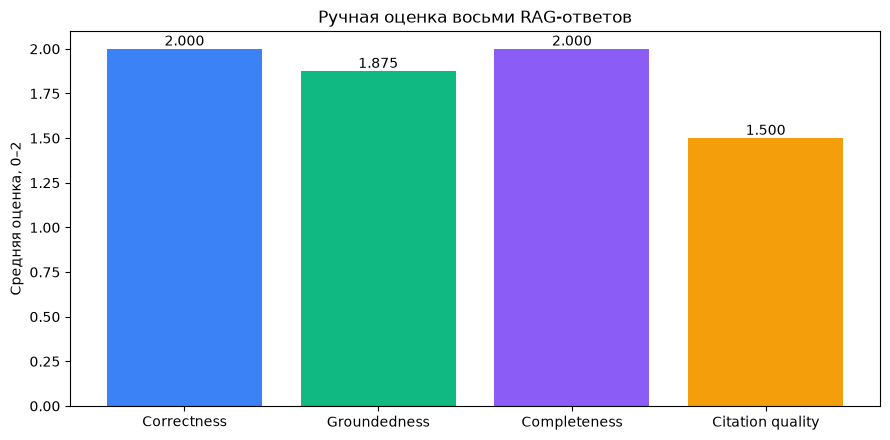

Сохранено: /Users/e.ilyina/Desktop/Портфолио/RAG/reports/results/analysis/figures/rag_manual_scores.png


In [4]:
manual = summary['manual_mean_scores']
labels = ['Correctness', 'Groundedness', 'Completeness', 'Citation quality']
keys = ['correctness_0_2', 'groundedness_0_2', 'completeness_0_2', 'citation_quality_0_2']
values = [manual[key] for key in keys]
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(labels, values, color=['#3b82f6', '#10b981', '#8b5cf6', '#f59e0b'])
ax.set_ylim(0, 2.1)
ax.set_ylabel('Средняя оценка, 0–2')
ax.set_title('Ручная оценка восьми RAG-ответов')
ax.bar_label(bars, fmt='%.3f')
fig.tight_layout()
figure_path = FIGURES_DIR / 'rag_manual_scores.png'
fig.savefig(figure_path, dpi=140)
plt.show()
print('Сохранено:', figure_path)

## 4. Типы ошибок

Ошибки retrieval, генерации и формата считаются отдельно: это показывает, какой компонент требует улучшения.

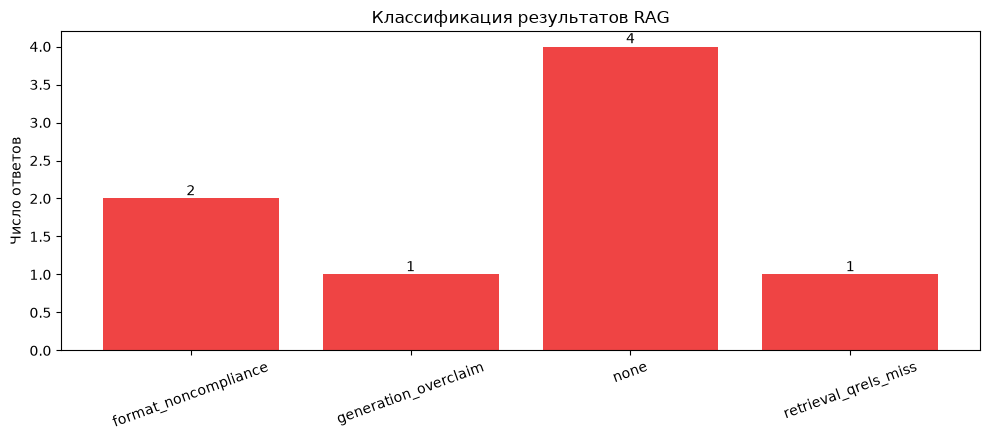

Сохранено: /Users/e.ilyina/Desktop/Портфолио/RAG/reports/results/analysis/figures/rag_error_types.png


In [5]:
error_counts = summary['error_counts']
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(error_counts.keys(), error_counts.values(), color='#ef4444')
ax.set_ylabel('Число ответов')
ax.set_title('Классификация результатов RAG')
ax.tick_params(axis='x', rotation=20)
ax.bar_label(bars)
fig.tight_layout()
figure_path = FIGURES_DIR / 'rag_error_types.png'
fig.savefig(figure_path, dpi=140)
plt.show()
print('Сохранено:', figure_path)

## 5. Структура Langfuse trace

Каждый query ID получает стабильную trace с root `chain`, дочерними observations `retriever`, `span`, `generation`, `evaluator` и шестью детерминированными scores. Повторный backfill проверяет локальный state и не создаёт дубликаты.

In [8]:
state_path = PROJECT_ROOT / 'reports/results/langfuse/backfill_state.json'
if state_path.exists():
    state = json.loads(state_path.read_text(encoding='utf-8'))
    print('Импортированных trace ID:', len(state['imported_trace_ids']))
else:
    print('Backfill state пока отсутствует: Cloud-импорт ещё не выполнялся.')

Импортированных trace ID: 8


Снимаок экрана с веб-версии Langfuse Cloud ![Снимок экрана 2026-11-23 в 17.14.44.png](<attachment:Снимок экрана 2026-11-23 в 17.14.44.png>)
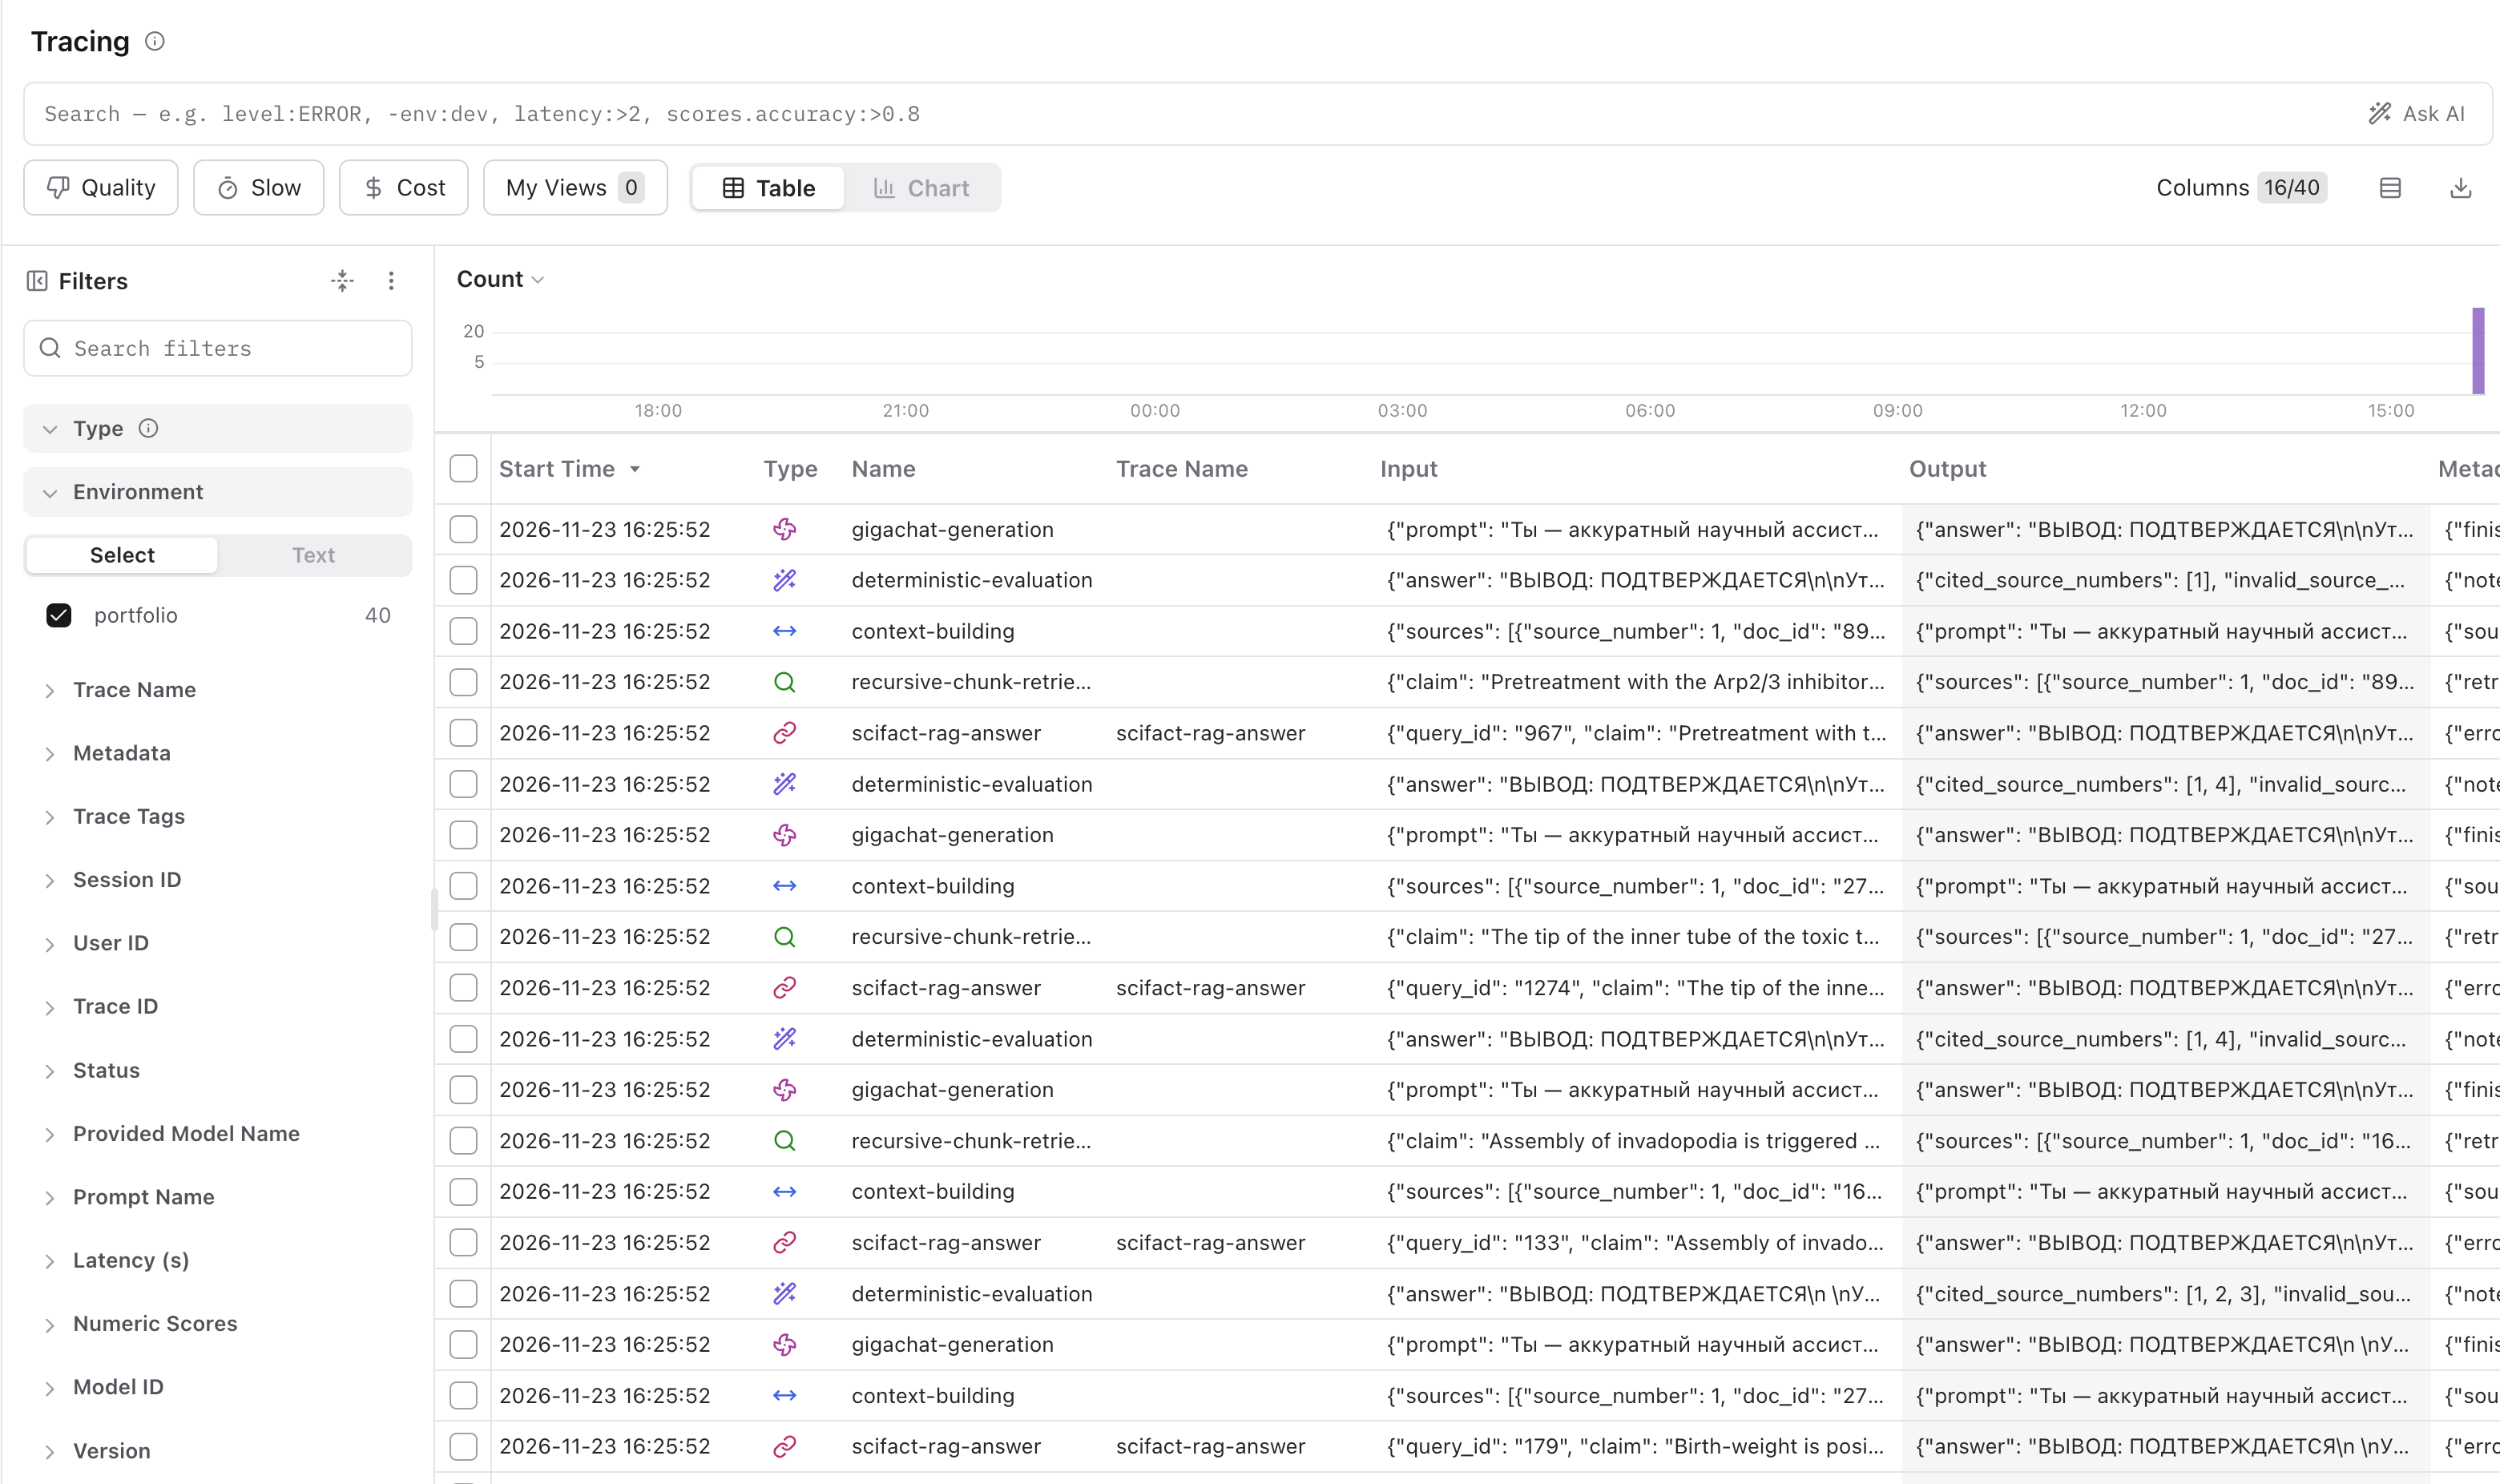

## 6. Итоговый отчёт

Отчёт строится детерминированно из CSV/JSON и явно фиксирует ограничения эксперимента.

In [7]:
report_path = PROJECT_ROOT / 'reports/final_report.md'
report_text = report_path.read_text(encoding='utf-8')
print('Строк в отчёте:', len(report_text.splitlines()))
print(report_text[:2500])

Строк в отчёте: 94
# Итоговый отчёт: RAG Playground

## Цель

Проект сравнивает документный и chunk-level retrieval на SciFact, а затем использует найденные
научные фрагменты как проверяемый контекст для `GigaChat-2`.

## Данные и воспроизводимость

- Корпус: 5 183 документа SciFact.
- Test split: 300 запросов с неизменённым document-level qrels.
- Dense-модель: локальная `BAAI/bge-small-en-v1.5`.
- Генерация: 8 заранее выбранных запросов, два подтверждённых batch по 4.
- Параметры chunking и retrieval зафиксированы до просмотра test-метрик.

## Сравнение retrieval

| Метод | Recall@1 | Recall@10 | MRR@10 | nDCG@10 | Recall@100 |
|---|---:|---:|---:|---:|---:|
| bm25_document | 0.5282 | 0.8173 | 0.6464 | 0.6826 | 0.9282 |
| chunk_fixed | 0.5701 | 0.8386 | 0.6802 | 0.7143 | 0.9517 |
| chunk_recursive | 0.5984 | 0.8340 | 0.6951 | 0.7249 | 0.9517 |
| chunk_sentence | 0.5859 | 0.8336 | 0.6882 | 0.7178 | 0.9550 |
| dense_document | 0.5759 | 0.8362 | 0.6822 | 0.7127 | 0.9417 |
| hybrid_docum

## 7. Финальные проверки

In [8]:
ruff = subprocess.run(
    [sys.executable, '-m', 'ruff', 'check', 'src', 'tests'],
    cwd=PROJECT_ROOT, check=True, capture_output=True, text=True,
)
tests = subprocess.run(
    [sys.executable, '-m', 'pytest'],
    cwd=PROJECT_ROOT, check=True, capture_output=True, text=True,
)
print('Ruff:', ruff.stdout.strip())
print('Pytest:', tests.stdout.strip())

Ruff: All checks passed!
Pytest: sss.....................................................                 [100%]
53 passed, 3 skipped in 2.89s


## Вывод

Все шесть этапов объединены в воспроизводимый эксперимент. Hybrid даёт максимальную полноту, recursive удобен для evidence, а Langfuse позволяет отдельно наблюдать retrieval, контекст, генерацию и оценку без новых генерационных запросов.